In [1]:
week3_plot.ipynb

NameError: name 'week3_plot' is not defined

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
print("Notebook is working")


Notebook is working


In [3]:
import gzip
import pandas as pd

path = "/home/phila/my-linux-notes/week2/fastqc_data/SRR5691197_100k.fastq.gz"

rows = []
with gzip.open(path, "rt") as f:
    for i, line in enumerate(f):
        if i % 4 == 3:  # quality line of each read
            quals = [ord(c) - 33 for c in line.strip()]
            rows.append({"read": len(rows), "mean_q": sum(quals) / len(quals), "length": len(quals)})
        if len(rows) >= 100000:
            break

df = pd.DataFrame(rows)
df.head()

,read,mean_q,length
0,0,36.705882,51
1,1,36.686275,51
2,2,36.745098,51
3,3,36.784314,51
4,4,36.568627,51


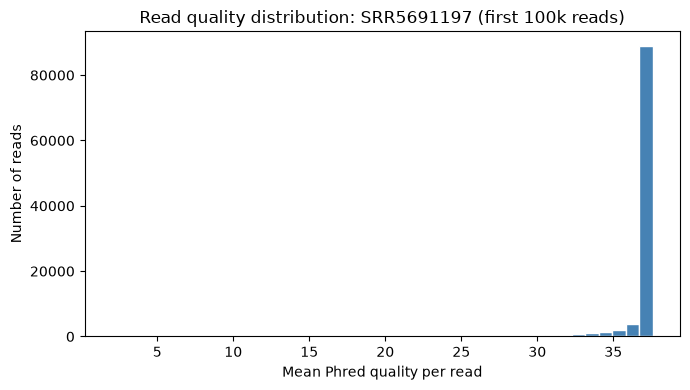

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.hist(df["mean_q"], bins=40, color="steelblue", edgecolor="white")
plt.xlabel("Mean Phred quality per read")
plt.ylabel("Number of reads")
plt.title("Read quality distribution: SRR5691197 (first 100k reads)")
plt.tight_layout()
plt.savefig("read_quality_hist.png", dpi=150)
plt.show()

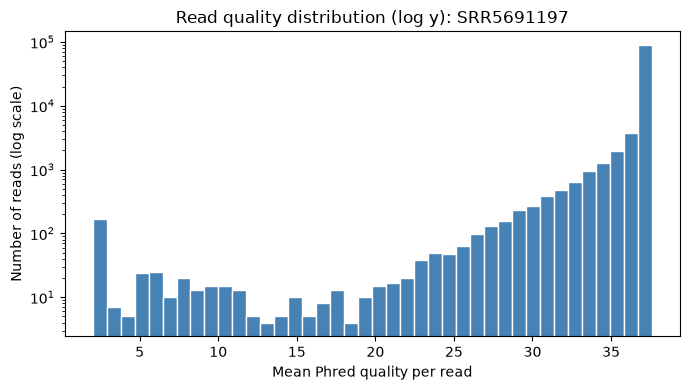

In [5]:
plt.figure(figsize=(7, 4))
plt.hist(df["mean_q"], bins=40, color="steelblue", edgecolor="white")
plt.yscale("log")
plt.xlabel("Mean Phred quality per read")
plt.ylabel("Number of reads (log scale)")
plt.title("Read quality distribution (log y): SRR5691197")
plt.tight_layout()
plt.savefig("read_quality_hist_log.png", dpi=150)
plt.show()

In [6]:
df["mean_q"].describe()

count    100000.000000
mean         37.044646
std           2.367935
min           2.000000
25%          37.450980
50%          37.568627
75%          37.607843
max          37.607843
Name: mean_q, dtype: float64

In [7]:
(df["mean_q"] < 30).sum(), (df["mean_q"] < 20).sum()

(np.int64(1352), np.int64(385))

The plot shows that the quality scores have a ceiling around 38. The distribution is left skewed with a tall spike and lower quality reads phasing off to the left. This corresponds with FastQC where the base pair quality was green throughout, meaning all reads were high quality.

In [8]:
df.sample(5000, random_state=1).to_csv("read_quality_sample.csv", index=False)